# 25. Singular Value Inequalities
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Weyl's majorant theorem for a non-normal matrix (a $10\times10$ triangular matrix with a random upper part). Left: eigenvalue moduli (blue) and singular values (red); the singular values spread out far more. Right: partial sums of logarithms, $\sum_{j\le k}\log|\lambda_j|$ and $\sum_{j\le k}\log s_j$. The singular value curve lies above for every $k$ and the two meet at $k=n$, where both equal $\log|\det A|$.

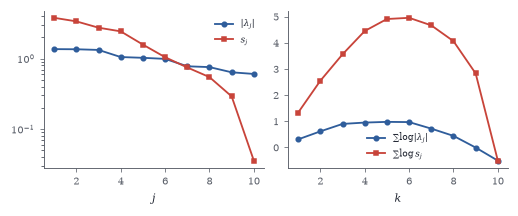

In [2]:
rng = np.random.default_rng(5); n = 10; T = np.triu(rng.normal(size=(n, n)), 1) * 0.9 + np.diag(rng.uniform(0.5, 1.5, n) * rng.choice([-1, 1], n))
lam_abs = np.sort(np.abs(np.linalg.eigvals(T)))[::-1]; sv = np.linalg.svd(T, compute_uv=False); k = np.arange(1, n + 1)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.85))
axs[0].semilogy(k, lam_abs, "o-", color=BLUE, ms=3, label=r"$|\lambda_j|$"); axs[0].semilogy(k, sv, "s-", color=RED, ms=3, label="$s_j$"); axs[0].set_xlabel("$j$"); axs[0].legend(fontsize=6)
axs[1].plot(k, np.cumsum(np.log(lam_abs)), "o-", color=BLUE, ms=3, label=r"$\sum\log|\lambda_j|$"); axs[1].plot(k, np.cumsum(np.log(sv)), "s-", color=RED, ms=3, label=r"$\sum\log s_j$")
axs[1].set_xlabel("$k$"); axs[1].legend(fontsize=6)

Yamamoto's theorem for a $4\times4$ non-normal matrix with eigenvalue moduli $1.2,1,0.8,0.6$ (dashed). The $m$-th roots of the singular values of $A^m$ start far from the eigenvalue moduli (at $m=1$ they are the singular values of $A$) and converge to them, slowly, at a rate governed by the ratios of consecutive eigenvalues. (Much larger $m$ would exceed the precision of floating-point arithmetic, since $s_4(A^m)/s_1(A^m)$ shrinks like $2^{-m}$; stable methods follow the product by repeated QR factorizations instead.)

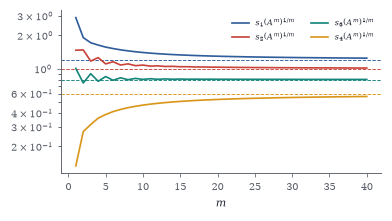

In [3]:
rng = np.random.default_rng(1); Q4, _ = np.linalg.qr(rng.normal(size=(4, 4))); lam4 = np.array([1.2, -1.0, 0.8, 0.6])
T4 = np.diag(lam4) + np.triu(rng.normal(size=(4, 4)) * 1.5, 1); A4 = Q4 @ T4 @ Q4.T
ms = np.arange(1, 41); P = np.eye(4); curves = []
for m in ms:
    P = P @ A4; curves.append(np.linalg.svd(P, compute_uv=False) ** (1 / m))
curves = np.array(curves)
fig, ax = plt.subplots(figsize=(W * 0.75, 1.9))
for j in range(4):
    ax.plot(ms, curves[:, j], color=PALETTE[j], lw=1.1, label=f"$s_{j+1}(A^m)^{{1/m}}$"); ax.axhline(abs(lam4[j]), color=PALETTE[j], ls="--", lw=0.6)
ax.set_xlabel("$m$"); ax.set_yscale("log"); ax.legend(fontsize=5.5, ncol=2)

Singular values of a product of $L$ independent $20\times20$ Gaussian matrices (entries of variance $1/20$), on a log scale, for increasing depth $L$. The spectrum spreads exponentially with depth (left), so most directions are crushed while a few grow. With orthogonal factors (right, grey), every product is orthogonal and all singular values stay at $1$.

Text(0.5, 1.0, 'orthogonal factors')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


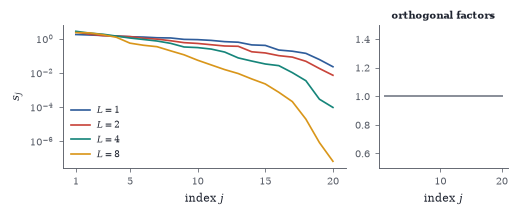

In [4]:
rng = np.random.default_rng(0); n = 20; depths = [1, 2, 4, 8]; out = {}
P = np.eye(n); Pq = np.eye(n)
for L in range(1, 9):
    P = rng.normal(size=(n, n)) / np.sqrt(n) @ P
    G, R = np.linalg.qr(rng.normal(size=(n, n))); Pq = (G * np.sign(np.diag(R))) @ Pq
    if L in depths: out[L] = (np.linalg.svd(P, compute_uv=False), np.linalg.svd(Pq, compute_uv=False))
fig, axs = plt.subplots(1, 2, figsize=(W, 1.85), gridspec_kw={"width_ratios": [2.2, 1]})
for i, L in enumerate(depths): axs[0].semilogy(np.arange(1, n + 1), out[L][0], color=PALETTE[i], lw=1.1, label=f"$L={L}$")
axs[0].set_xlabel("index $j$"); axs[0].set_ylabel("$s_j$"); axs[0].legend(fontsize=6); axs[0].set_xticks([1, 5, 10, 15, 20])
for i, L in enumerate(depths): axs[1].plot(np.arange(1, n + 1), out[L][1], color=GRAY, lw=1)
axs[1].set_ylim(0.5, 1.5); axs[1].set_xlabel("index $j$"); axs[1].set_title("orthogonal factors", fontsize=6.5)

The Bhatia–Kittaneh inequality, singular value by singular value. For random $8\times8$ matrices $A,B$, the singular values of $AB^*$ (blue) lie below half those of $A^*A+B^*B$ (red outline) at every index, not just in sum.

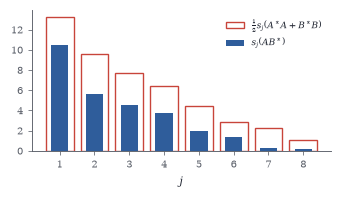

In [5]:
rng = np.random.default_rng(12); Ab = rng.normal(size=(8, 8)); Bb = rng.normal(size=(8, 8)) @ np.diag(np.linspace(1.5, 0.1, 8))
lhs = np.linalg.svd(Ab @ Bb.T, compute_uv=False); rhs = 0.5 * np.linalg.svd(Ab.T @ Ab + Bb.T @ Bb, compute_uv=False)
fig, ax = plt.subplots(figsize=(W * 0.65, 1.7)); j = np.arange(1, 9)
ax.bar(j, rhs, color="none", edgecolor=RED, lw=0.9, label=r"$\frac{1}{2} s_j(A^*A+B^*B)$"); ax.bar(j, lhs, width=0.5, color=BLUE, label=r"$s_j(AB^*)$")
ax.set_xlabel("$j$"); ax.legend(fontsize=6)

In [6]:
from itertools import combinations
rng = np.random.default_rng(3); n = 6; Ag = rng.normal(size=(n, n)); Bg = rng.normal(size=(n, n))
sA, sB, sAB = [np.linalg.svd(M, compute_uv=False) for M in (Ag, Bg, Ag @ Bg)]
slack = min(np.log(sA[list(I)]).sum() + np.log(sB[:len(I)]).sum() - np.log(sAB[list(I)]).sum() for k in range(1, n + 1) for I in combinations(range(n), k))
print("smallest slack over all index sets (log scale):", round(slack, 12))

smallest slack over all index sets (log scale): -0.0


In [7]:
rng = np.random.default_rng(0); m = 20000; Qc = np.eye(3); acc = np.zeros(3)
for _ in range(m):
    Qc, Rc = np.linalg.qr(rng.normal(size=(3, 3)) @ Qc); acc += np.log(np.abs(np.diag(Rc)))
print("Lyapunov exponents (QR method):", np.round(acc / m, 3))
from scipy.special import digamma
print("exact values (Newman): ", np.round([0.5 * (np.log(2) + digamma((3 - k) / 2)) for k in range(3)], 3))

Lyapunov exponents (QR method): [ 0.368  0.05  -0.634]


exact values (Newman):  [ 0.365  0.058 -0.635]


In [8]:
A2 = np.array([[1, 10], [0, 0.5]])
for m in (1, 5, 25, 125):
    s = np.linalg.svd(np.linalg.matrix_power(A2, m), compute_uv=False) ** (1 / m); print(m, np.round(s, 4))

1 [10.0622  0.0497]
5 [1.8095 0.2763]
25 [1.1274 0.4435]
125 [1.0243 0.4882]
